# 08 – Portfolio Analysis
Builds four portfolios (Equal-weight, Defensive, Growth, Minimum variance) from the 10 stocks and compares their return and risk.

**Input:** `data/processed/market_clean.csv`
**Outputs:** `portfolio_weights.csv`, `portfolio_daily.csv`, `portfolio_metrics.csv` (in `data/processed/`)

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# find the repo root (works whether the notebook runs from the root or from notebooks/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA = ROOT / "data" / "processed"

TRADING_DAYS = 252   # trading days per year
RISK_FREE = 0.0      # risk-free rate = 0
print("Data folder:", DATA)

Data folder: d:\DEPI\MarketPulse Graduation Project\data\processed


## 2. Load daily returns
`return` in `market_clean.csv` is the simple return `close_t / close_(t-1) - 1`. We reshape it so each row is a date and each column is a stock. The first day has no return, so it is dropped.

In [2]:
market = pd.read_csv(DATA / "market_clean.csv", parse_dates=["date"])
returns = (market.pivot(index="date", columns="ticker", values="return")
                 .sort_index()
                 .dropna())
tickers = sorted(returns.columns)
returns = returns[tickers]
n = len(tickers)
print(f"{n} stocks, {len(returns)} trading days: {returns.index.min().date()} -> {returns.index.max().date()}")
returns.head()

10 stocks, 1253 trading days: 2021-01-05 -> 2025-12-30


ticker,AAPL,AMZN,JNJ,JPM,KO,LLY,MSFT,NVDA,TSLA,XOM
date,,,,,,,,,,
2021-01-05,0.012363,0.010004,0.011757,0.005441,-0.010993,0.004955,0.000965,0.022210,0.007317,0.048193
2021-01-06,-0.033661,-0.024897,0.009410,0.046956,-0.031813,-0.012025,-0.025929,-0.058953,0.028390,0.025517
2021-01-07,0.034124,0.007577,0.003379,0.032839,-0.011085,0.009189,0.028457,0.057830,0.079447,0.007846
2021-01-08,0.008631,0.006496,-0.002058,0.001104,0.022418,0.003497,0.006093,-0.005040,0.078403,0.011121
2021-01-11,-0.023249,-0.021519,-0.004186,0.014924,-0.017228,0.117361,-0.009698,0.025966,-0.078214,0.030356


## 3. Define the four portfolios
A weight is the share of the portfolio held in each stock; weights must sum to 1.

The **minimum-variance** weights come from an optimizer: it searches for the weights with the lowest portfolio variance, subject to **long-only** (w >= 0) and **sum = 1**.

In [3]:
def fixed_weights(selected):
    """Equal weight on the selected tickers, zero on the rest."""
    return {t: (1 / len(selected) if t in selected else 0.0) for t in tickers}


def min_variance_weights(ret):
    """Long-only minimum-variance weights."""
    cov = ret.cov().values
    result = minimize(
        lambda w: w @ cov @ w,                 # portfolio variance
        x0=np.ones(n) / n,
        jac=lambda w: 2 * cov @ w,
        method="SLSQP",
        bounds=[(0, 1)] * n,                   # long-only
        constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
        options={"ftol": 1e-15, "maxiter": 1000},
    )
    if not result.success:
        raise RuntimeError(f"Optimization failed: {result.message}")
    w = np.clip(result.x, 0, None)
    return dict(zip(tickers, w / w.sum()))


portfolios = {
    "P1": ("Equal-weight",     {t: 1 / n for t in tickers}),
    "P2": ("Defensive",        fixed_weights(["JNJ", "KO", "LLY", "XOM", "JPM"])),
    "P3": ("Growth",           fixed_weights(["AAPL", "MSFT", "NVDA", "AMZN", "TSLA"])),
    "P4": ("Minimum variance", min_variance_weights(returns)),
}

pd.DataFrame({pid: w for pid, (name, w) in portfolios.items()}).round(4)

,P1,P2,P3,P4
AAPL,0.1,0.0,0.2,0.0000
AMZN,0.1,0.0,0.2,0.0150
JNJ,0.1,0.2,0.0,0.3217
JPM,0.1,0.2,0.0,0.0570
KO,0.1,0.2,0.0,0.3429
LLY,0.1,0.2,0.0,0.0321
MSFT,0.1,0.0,0.2,0.1120
NVDA,0.1,0.0,0.2,0.0064
TSLA,0.1,0.0,0.2,0.0002
XOM,0.1,0.2,0.0,0.1127


## 4. Daily returns, value index, drawdown and metrics
- Daily return: `R_p = sum(w_i * R_i)`
- Value index: starts at 100, `100 * cumprod(1 + R_p)`
- Drawdown: `value / running peak - 1`
- Annualized return = mean daily return x 252; annualized volatility = daily std x sqrt(252); Sharpe = return / volatility (risk-free = 0)
- Historical VaR 95% = 5th percentile of daily returns (negative number = loss)

In [4]:
weight_rows, daily_frames, metric_rows = [], [], []

for pid, (name, w) in portfolios.items():
    wv = np.array([w[t] for t in tickers])
    assert abs(wv.sum() - 1) < 1e-9, f"{pid} weights do not sum to 1"
    weight_rows += [(pid, t, w[t]) for t in tickers]

    r = returns.values @ wv                                   # portfolio daily return
    value_index = 100 * np.cumprod(1 + r)                     # starts at 100
    peak = np.maximum.accumulate(np.r_[100, value_index])[1:] # running peak (includes the start of 100)
    drawdown = value_index / peak - 1

    daily_frames.append(pd.DataFrame({
        "portfolio_id": pid,
        "date": returns.index.strftime("%Y-%m-%d"),
        "daily_return": r,
        "value_index": value_index,
        "drawdown": drawdown,
    }))

    ann_return = r.mean() * TRADING_DAYS
    ann_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    metric_rows.append({
        "portfolio_id": pid,
        "portfolio_name": name,
        "ann_return": ann_return,
        "ann_vol": ann_vol,
        "sharpe": (ann_return - RISK_FREE) / ann_vol,
        "max_drawdown": drawdown.min(),
        "var_95_hist": np.percentile(r, 5),
    })

weights_df = pd.DataFrame(weight_rows, columns=["portfolio_id", "ticker", "weight"])
daily_df = pd.concat(daily_frames, ignore_index=True)
metrics_df = pd.DataFrame(metric_rows)
metrics_df.round(4)

,portfolio_id,portfolio_name,ann_return,ann_vol,sharpe,max_drawdown,var_95_hist
0,P1,Equal-weight,0.2691,0.1936,1.3897,-0.2116,-0.0188
1,P2,Defensive,0.2351,0.1424,1.6506,-0.1202,-0.0135
2,P3,Growth,0.3031,0.3190,0.9502,-0.4849,-0.0325
3,P4,Minimum variance,0.1563,0.1228,1.2726,-0.1114,-0.0119


## 5. Completion checks

In [5]:
# 1) each portfolio's weights sum to 1
sums = weights_df.groupby("portfolio_id")["weight"].sum()
assert np.allclose(sums, 1)
print("Weights sum to 1 for every portfolio:", sums.round(6).to_dict())

# 2) equal-weight volatility < average individual-stock volatility
avg_indiv_vol = (returns.std(ddof=1) * np.sqrt(TRADING_DAYS)).mean()
ew_vol = metrics_df.loc[metrics_df.portfolio_id == "P1", "ann_vol"].iloc[0]
assert ew_vol < avg_indiv_vol
print(f"Equal-weight vol {ew_vol:.4f} < average individual-stock vol {avg_indiv_vol:.4f}")

Weights sum to 1 for every portfolio: {'P1': 1.0, 'P2': 1.0, 'P3': 1.0, 'P4': 1.0}
Equal-weight vol 0.1936 < average individual-stock vol 0.3176


## 6. Charts

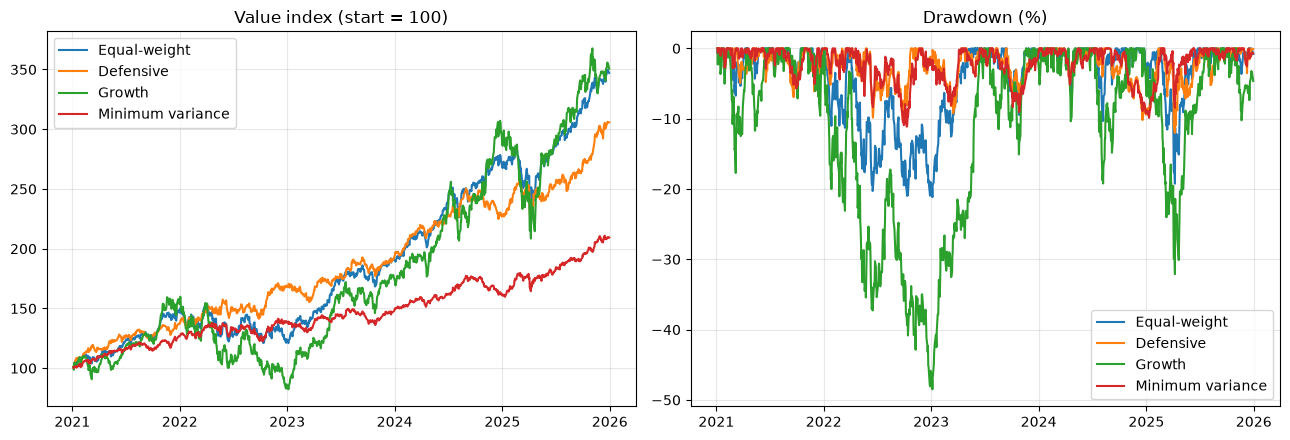

In [6]:
import matplotlib.pyplot as plt

names = {pid: name for pid, (name, _) in portfolios.items()}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for pid, g in daily_df.groupby("portfolio_id"):
    d = pd.to_datetime(g["date"])
    axes[0].plot(d, g["value_index"], label=names[pid])
    axes[1].plot(d, g["drawdown"] * 100, label=names[pid])
axes[0].set_title("Value index (start = 100)")
axes[1].set_title("Drawdown (%)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Save outputs

In [7]:
weights_df.to_csv(DATA / "portfolio_weights.csv", index=False, float_format="%.10f")
daily_df.to_csv(DATA / "portfolio_daily.csv", index=False, float_format="%.8f")
metrics_df.round(6).to_csv(DATA / "portfolio_metrics.csv", index=False)
print("Saved 3 files to", DATA)

Saved 3 files to d:\DEPI\MarketPulse Graduation Project\data\processed


## Limitation: in-sample bias (minimum-variance portfolio)
The minimum-variance weights were **estimated and evaluated on the same 2021-2025 data**. Its volatility, drawdown and VaR are therefore *in-sample* and optimistic: they show how the portfolio would have behaved had the weights been known in advance, not how it should perform on new data. Covariances also change over time. A fairer test would fit the weights on an earlier window and evaluate them on a later one (walk-forward / train-test split).